**Step 1 - Import libraries and load the dataset**

In [ ]:
import pandas as pd
import numpy as np

# Load the original dataset
url = "https://raw.githubusercontent.com/krishnaik06/playstore-Dataset/main/googleplaystore.csv"

df = pd.read_csv(url)

# Create a working copy
df = df.copy()

# Display the first 5 rows
print("First 5 rows:")
print(df.head())

# Check dataset size
print("\nOriginal dataset shape:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()


**Step 2 - Explore data quality**

To understand the quality of the original data before making changes.

In [36]:
# Missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check app names that appear more than once
print("\nDuplicate app names:", df["App"].duplicated().sum())

# Check important categorical columns
print("\nApp types:")
print(df["Type"].value_counts(dropna=False))

print("\nCategories:")
print(df["Category"].value_counts(dropna=False).head(10))

print("\nRatings summary:")
print(df["Rating"].describe())


Missing values:
App                  0
Category             0
Rating            1463
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
Size_MB           1228
Update_Year          0
dtype: int64

Duplicate rows: 0

Duplicate app names: 0

App types:
Type
Free    8904
Paid     754
<NA>       1
Name: count, dtype: Int64

Categories:
Category
FAMILY             1877
GAME                945
TOOLS               829
BUSINESS            420
MEDICAL             395
PERSONALIZATION     376
PRODUCTIVITY        374
LIFESTYLE           369
FINANCE             345
SPORTS              325
Name: count, dtype: int64

Ratings summary:
count    8196.000000
mean        4.173267
std         0.536253
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max         5.000000
Name: Rating, dtype: float6

**Step 3 - Clean the data**

This version avoids the warning you received by explicitly selecting both object and str data types.

In [37]:
# Remove unnecessary spaces from text columns
text_columns = df.select_dtypes(
    include=["object", "str"]
).columns

for col in text_columns:
    df[col] = df[col].str.strip()

print("Text columns cleaned.")


Text columns cleaned.


**Step 4 - Remove invalid records and handle missing values**

The Dataset has a known malformed record where a category value is numeric rather than a valid category name. 
We will remove that record and retain missing ratings for now instead of inventing ratings. 
Why retain missing ratings? An app with no recorded rating is not necessarily a bad app. 
Keeping it allows you to analyze app counts and installs while excluding missing ratings from rating calculations.


In [38]:
# Remove rows without an app name
df = df.dropna(subset=["App"])

# Remove rows with missing or invalid categories
df = df[df["Category"].notna()]

# Keep category names containing letters
df = df[
    df["Category"].str.contains(
        r"[A-Za-z]", na=False
    )
]

# Convert Rating to numeric
df["Rating"] = pd.to_numeric(
    df["Rating"], errors="coerce"
)

# Ratings must be between 1 and 5 when available
df.loc[
    ~df["Rating"].between(1, 5),
    "Rating"
] = np.nan

print("Rows after basic validation:", len(df))
print("\nMissing values after validation:")
print(df.isnull().sum())


Rows after basic validation: 9659

Missing values after validation:
App                  0
Category             0
Rating            1463
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
Size_MB           1228
Update_Year          0
dtype: int64


**Step 5 - Clean Reviews, Installs and Price**

This section fixes the .str error you encountered by converting values to text before removing symbols.

In [39]:

# Clean Reviews
df["Reviews"] = pd.to_numeric(
    df["Reviews"], errors="coerce"
)

# Clean Installs
df["Installs"] = (
    df["Installs"]
    .astype("string")
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
)

df["Installs"] = pd.to_numeric(
    df["Installs"], errors="coerce"
)

# Clean Price
df["Price"] = (
    df["Price"]
    .astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
)

df["Price"] = pd.to_numeric(
    df["Price"], errors="coerce"
)

print(df[["Reviews", "Installs", "Price"]].head())
print("\nNumeric data types:")
print(df[["Reviews", "Installs", "Price"]].dtypes)

    Reviews    Installs  Price
0  78158306  1000000000    0.0
1  69119316  1000000000    0.0
2  66577446  1000000000    0.0
3  56646578  1000000000    0.0
4  44893888   100000000    0.0

Numeric data types:
Reviews       int64
Installs      Int64
Price       Float64
dtype: object


**Step 6 - Convert app size into MB**

The original Size column contains values such as 19M, 14k, and Varies with device. 
Convert the readable sizes into numeric values so you can analyze them.
We keep the original Size column and create Size_MB for analysis. 
This makes it easier to check whether the conversion worked.

In [40]:

# Function to convert app size to MB
def convert_size(size):

    if pd.isna(size):
        return np.nan

    size = str(size).strip()

    if size == "Varies with device":
        return np.nan

    try:
        if size.endswith("M"):
            return float(size[:-1])

        elif size.endswith("k"):
            return float(size[:-1]) / 1024

        else:
            return np.nan

    except ValueError:
        return np.nan


# Create a new numeric column
df["Size_MB"] = df["Size"].apply(convert_size)

print(df[["Size", "Size_MB"]].head(10))


                 Size  Size_MB
0  Varies with device      NaN
1  Varies with device      NaN
2  Varies with device      NaN
3  Varies with device      NaN
4                 98M     98.0
5  Varies with device      NaN
6                 76M     76.0
7  Varies with device      NaN
8  Varies with device      NaN
9                 97M     97.0


**Step 7 - Clean the Type column**

In [41]:

# Keep only valid app types
df["Type"] = df["Type"].astype("string").str.strip()

df.loc[
    ~df["Type"].isin(["Free", "Paid"]),
    "Type"
] = pd.NA

# Check app type counts
print(df["Type"].value_counts(dropna=False))


Type
Free    8904
Paid     754
<NA>       1
Name: count, dtype: Int64


**Step 8 - Convert dates and clean Android versions**

In [42]:

# Convert Last Updated to datetime
df["Last Updated"] = pd.to_datetime(
    df["Last Updated"], errors="coerce"
)

# Extract update year
df["Update_Year"] = df["Last Updated"].dt.year

# Clean Android version text
df["Android Ver"] = (
    df["Android Ver"]
    .astype("string")
    .str.strip()
)

# Check results
print(df[["Last Updated", "Update_Year", "Android Ver"]].head())
print("\nMissing update dates:", df["Last Updated"].isna().sum())


  Last Updated  Update_Year         Android Ver
0   2018-08-03         2018  Varies with device
1   2018-08-03         2018  Varies with device
2   2018-07-31         2018  Varies with device
3   2018-08-01         2018  Varies with device
4   2018-07-15         2018          4.1 and up

Missing update dates: 0


**Step 9 — Check and remove duplicate app records**

An app can appear more than once in the dataset. For this project, we will keep the record with the highest number of reviews.

**Why do this?** If your analysis counts each app only once, duplicate app names can inflate category counts and distort summaries. 
However, keeping one record per name is a project assumption, not a universal rule. 
Document it in your report.

In [43]:

# Sort by Reviews, highest first
df = df.sort_values(
    "Reviews",
    ascending=False,
    na_position="last"
)

# Keep one record per app name
df = df.drop_duplicates(
    subset="App",
    keep="first"
)

# Reset row numbering
df = df.reset_index(drop=True)

print("Rows after removing duplicate app names:", len(df))
print("Remaining duplicate app names:", df["App"].duplicated().sum())


Rows after removing duplicate app names: 9659
Remaining duplicate app names: 0


**Step 10 — Final validation**

In [44]:

# Create final cleaned dataset
clean_df = df.copy()

print("FINAL DATA QUALITY REPORT")
print("-" * 40)

print("Final dataset shape:", clean_df.shape)

print("\nMissing values:")
print(clean_df.isnull().sum())

print("\nDuplicate rows:", clean_df.duplicated().sum())

print("\nDuplicate app names:", clean_df["App"].duplicated().sum())

print("\nRatings outside valid range:")
print(
    (
        clean_df["Rating"].notna()
        & ~clean_df["Rating"].between(1, 5)
    ).sum()
)

print("\nApp types:")
print(clean_df["Type"].value_counts(dropna=False))

print("\nFinal data types:")
print(clean_df.dtypes)

print("\nFirst 5 cleaned rows:")
print(clean_df.head())


FINAL DATA QUALITY REPORT
----------------------------------------
Final dataset shape: (9659, 15)

Missing values:
App                  0
Category             0
Rating            1463
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
Size_MB           1228
Update_Year          0
dtype: int64

Duplicate rows: 0

Duplicate app names: 0

Ratings outside valid range:
0

App types:
Type
Free    8904
Paid     754
<NA>       1
Name: count, dtype: Int64

Final data types:
App                          str
Category                     str
Rating                   float64
Reviews                    int64
Size                         str
Installs                   Int64
Type                      string
Price                    Float64
Content Rating               str
Genres                       str
Last Updated      da

**Step 11 — Save the cleaned dataset**

In [45]:

# Save the cleaned dataset for SQL and Power BI
clean_df.to_csv(
    "googleplaystore_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


**Step 12 — To check that directory**

In [46]:
import os

print(os.getcwd())

C:\Users\Sukanya


**Exploratory Data Analysis (EDA)**

In [47]:
print("Dataset shape:", clean_df.shape)

display(clean_df.head())

clean_df.info()

print(clean_df.isnull().sum())

print("Duplicate rows:", clean_df.duplicated().sum())

display(clean_df.describe())

Dataset shape: (9659, 15)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB,Update_Year
0,Facebook,SOCIAL,4.1,78158306,Varies with device,1000000000,Free,0.0,Teen,Social,2018-08-03,Varies with device,Varies with device,NaN,2018
1,WhatsApp Messenger,COMMUNICATION,4.4,69119316,Varies with device,1000000000,Free,0.0,Everyone,Communication,2018-08-03,Varies with device,Varies with device,NaN,2018
2,Instagram,SOCIAL,4.5,66577446,Varies with device,1000000000,Free,0.0,Teen,Social,2018-07-31,Varies with device,Varies with device,NaN,2018
3,Messenger – Text and Video Chat for Free,COMMUNICATION,4.0,56646578,Varies with device,1000000000,Free,0.0,Everyone,Communication,2018-08-01,Varies with device,Varies with device,NaN,2018
4,Clash of Clans,GAME,4.6,44893888,98M,100000000,Free,0.0,Everyone 10+,Strategy,2018-07-15,10.322.16,4.1 and up,98.0,2018


<class 'pandas.DataFrame'>
RangeIndex: 9659 entries, 0 to 9658
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             9659 non-null   str           
 1   Category        9659 non-null   str           
 2   Rating          8196 non-null   float64       
 3   Reviews         9659 non-null   int64         
 4   Size            9659 non-null   str           
 5   Installs        9659 non-null   Int64         
 6   Type            9658 non-null   string        
 7   Price           9659 non-null   Float64       
 8   Content Rating  9659 non-null   str           
 9   Genres          9659 non-null   str           
 10  Last Updated    9659 non-null   datetime64[us]
 11  Current Ver     9651 non-null   str           
 12  Android Ver     9657 non-null   string        
 13  Size_MB         8431 non-null   float64       
 14  Update_Year     9659 non-null   int32         
dtypes: Float64(1), 

,Rating,Reviews,Installs,Price,Last Updated,Size_MB,Update_Year
count,8196.000000,9.659000e+03,9659.0,9659.0,9659,8431.000000,9659.000000
mean,4.173267,2.168041e+05,7798170.248162,1.097231,2017-10-30 23:45:23.387514,20.398075,2017.346206
min,1.000000,0.000000e+00,0.0,0.0,2010-05-21 00:00:00,0.008301,2010.000000
25%,4.000000,2.500000e+01,1000.0,0.0,2017-08-07 00:00:00,4.600000,2017.000000
50%,4.300000,9.690000e+02,100000.0,0.0,2018-05-04 00:00:00,12.000000,2018.000000
75%,4.500000,2.945350e+04,1000000.0,0.0,2018-07-17 00:00:00,28.000000,2018.000000
max,5.000000,7.815831e+07,1000000000.0,400.0,2018-08-08 00:00:00,100.000000,2018.000000
std,0.536253,1.831430e+06,53769728.818071,16.851618,NaN,21.828959,1.137397


**Step 1 — Understand your cleaned dataset**

**What are we checking?**
- Shape: how many app records and columns remain after cleaning.
- Missing values: which fields may need special handling during analysis.
- Data types: whether ratings, reviews, installs, prices and app sizes are numeric.
- Summary statistics: typical values, minimums, maximums and spread.

Don't remove more data just because a column has missing values. First decide whether that column is needed for a particular research question.

In [48]:

# 1. Check the number of rows and columns
print("Dataset shape:", clean_df.shape)

# 2. Display the first 5 rows
display(clean_df.head())

# 3. Check column names and data types
clean_df.info()

# 4. Check missing values
print("\nMissing values in each column:")
print(clean_df.isnull().sum())

# 5. Check duplicate records
print("\nDuplicate rows:", clean_df.duplicated().sum())

# 6. Get summary statistics for numeric columns
display(clean_df.describe())


Dataset shape: (9659, 15)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB,Update_Year
0,Facebook,SOCIAL,4.1,78158306,Varies with device,1000000000,Free,0.0,Teen,Social,2018-08-03,Varies with device,Varies with device,NaN,2018
1,WhatsApp Messenger,COMMUNICATION,4.4,69119316,Varies with device,1000000000,Free,0.0,Everyone,Communication,2018-08-03,Varies with device,Varies with device,NaN,2018
2,Instagram,SOCIAL,4.5,66577446,Varies with device,1000000000,Free,0.0,Teen,Social,2018-07-31,Varies with device,Varies with device,NaN,2018
3,Messenger – Text and Video Chat for Free,COMMUNICATION,4.0,56646578,Varies with device,1000000000,Free,0.0,Everyone,Communication,2018-08-01,Varies with device,Varies with device,NaN,2018
4,Clash of Clans,GAME,4.6,44893888,98M,100000000,Free,0.0,Everyone 10+,Strategy,2018-07-15,10.322.16,4.1 and up,98.0,2018


<class 'pandas.DataFrame'>
RangeIndex: 9659 entries, 0 to 9658
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             9659 non-null   str           
 1   Category        9659 non-null   str           
 2   Rating          8196 non-null   float64       
 3   Reviews         9659 non-null   int64         
 4   Size            9659 non-null   str           
 5   Installs        9659 non-null   Int64         
 6   Type            9658 non-null   string        
 7   Price           9659 non-null   Float64       
 8   Content Rating  9659 non-null   str           
 9   Genres          9659 non-null   str           
 10  Last Updated    9659 non-null   datetime64[us]
 11  Current Ver     9651 non-null   str           
 12  Android Ver     9657 non-null   string        
 13  Size_MB         8431 non-null   float64       
 14  Update_Year     9659 non-null   int32         
dtypes: Float64(1), 

,Rating,Reviews,Installs,Price,Last Updated,Size_MB,Update_Year
count,8196.000000,9.659000e+03,9659.0,9659.0,9659,8431.000000,9659.000000
mean,4.173267,2.168041e+05,7798170.248162,1.097231,2017-10-30 23:45:23.387514,20.398075,2017.346206
min,1.000000,0.000000e+00,0.0,0.0,2010-05-21 00:00:00,0.008301,2010.000000
25%,4.000000,2.500000e+01,1000.0,0.0,2017-08-07 00:00:00,4.600000,2017.000000
50%,4.300000,9.690000e+02,100000.0,0.0,2018-05-04 00:00:00,12.000000,2018.000000
75%,4.500000,2.945350e+04,1000000.0,0.0,2018-07-17 00:00:00,28.000000,2018.000000
max,5.000000,7.815831e+07,1000000000.0,400.0,2018-08-08 00:00:00,100.000000,2018.000000
std,0.536253,1.831430e+06,53769728.818071,16.851618,NaN,21.828959,1.137397


**Step 2 — Analyze categorical columns**

Categorical columns describe groups, such as category, app type, and content rating.

In [49]:

import matplotlib.pyplot as plt
import seaborn as sns

categorical_columns = [
    "Category",
    "Type",
    "Content Rating",
    "Genres"
]

for col in categorical_columns:
    print(f"\nValue counts for {col}:")
    print(clean_df[col].value_counts().head(10))



Value counts for Category:
Category
FAMILY             1877
GAME                945
TOOLS               829
BUSINESS            420
MEDICAL             395
PERSONALIZATION     376
PRODUCTIVITY        374
LIFESTYLE           369
FINANCE             345
SPORTS              325
Name: count, dtype: int64

Value counts for Type:
Type
Free    8904
Paid     754
Name: count, dtype: Int64

Value counts for Content Rating:
Content Rating
Everyone           7903
Teen               1036
Mature 17+          393
Everyone 10+        322
Adults only 18+       3
Unrated               2
Name: count, dtype: int64

Value counts for Genres:
Genres
Tools              828
Entertainment      561
Education          510
Business           420
Medical            395
Personalization    376
Productivity       374
Lifestyle          368
Finance            345
Sports             331
Name: count, dtype: int64


Now **visualize** the three most useful **categorical columns.**

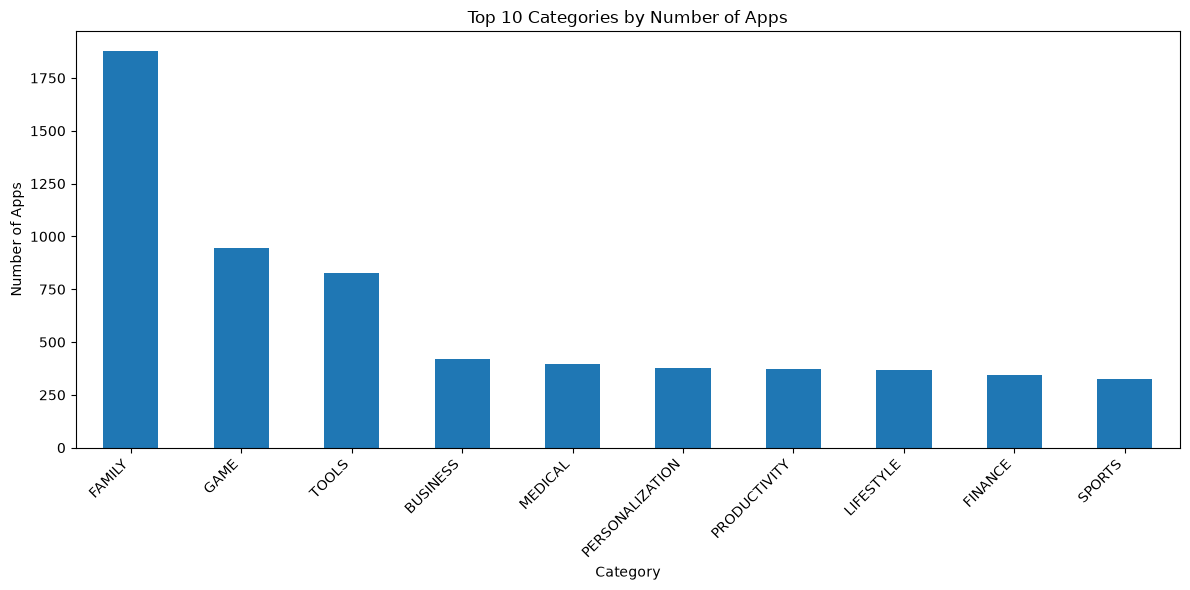

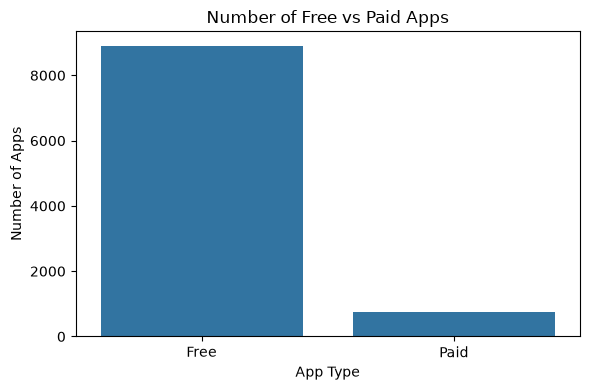

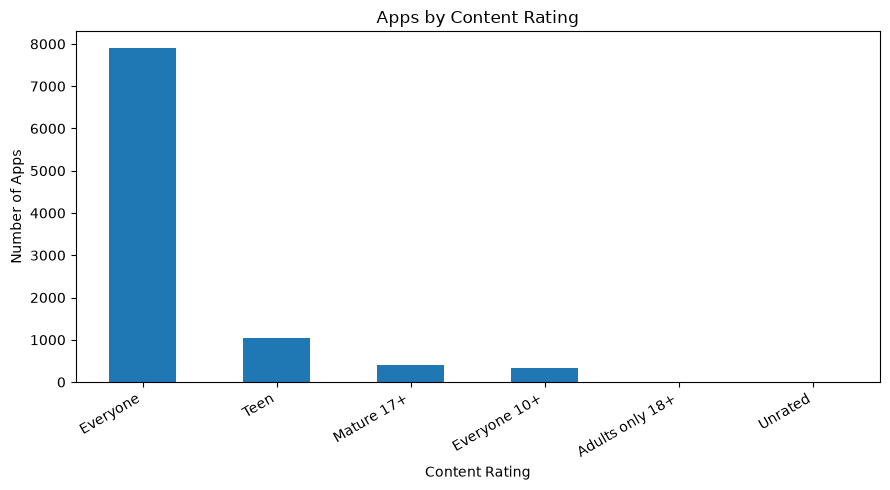

In [50]:

# 1. Number of apps in each category
plt.figure(figsize=(12, 6))

clean_df["Category"].value_counts().head(10).plot(
    kind="bar"
)

plt.title("Top 10 Categories by Number of Apps")
plt.xlabel("Category")
plt.ylabel("Number of Apps")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# 2. Free vs Paid apps
plt.figure(figsize=(6, 4))

sns.countplot(data=clean_df, x="Type")

plt.title("Number of Free vs Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()


# 3. Content rating distribution
plt.figure(figsize=(9, 5))

clean_df["Content Rating"].value_counts().plot(
    kind="bar"
)

plt.title("Apps by Content Rating")
plt.xlabel("Content Rating")
plt.ylabel("Number of Apps")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


**Category columns Observations**

# 1. Number of apps in each category
The FAMILY category contains the highest number of apps, followed by GAME and TOOLS.
The dataset has a larger number of apps in the FAMILY category than in other categories. This shows that FAMILY is the most represented category in this dataset.

# 2. Free vs Paid apps
Free apps are much more common than paid apps. 
The graph shows that the number of free apps is significantly higher than the number of paid apps. This suggests that developers in the dataset predominantly offer apps for free.

# 3. Content rating distribution**
The Everyone content-rating group appears most frequently.
Most apps in the dataset are rated for Everyone, followed by Teen. This indicates that many apps are labelled as suitable for a broad audience.

**Step 3 — Analyze numerical columns**

In [51]:

numeric_columns = [
    "Rating",
    "Reviews",
    "Installs",
    "Price",
    "Size_MB"
]

print(clean_df[numeric_columns].describe().round(2))


        Rating      Reviews      Installs   Price  Size_MB
count  8196.00      9659.00        9659.0  9659.0  8431.00
mean      4.17    216804.11    7798170.25     1.1    20.40
std       0.54   1831430.21   53769728.82   16.85    21.83
min       1.00         0.00           0.0     0.0     0.01
25%       4.00        25.00        1000.0     0.0     4.60
50%       4.30       969.00      100000.0     0.0    12.00
75%       4.50     29453.50     1000000.0     0.0    28.00
max       5.00  78158306.00  1000000000.0   400.0   100.00


#histograms to understand the distributions.

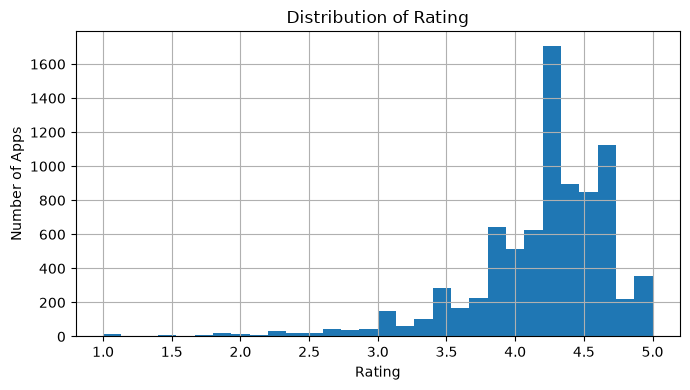

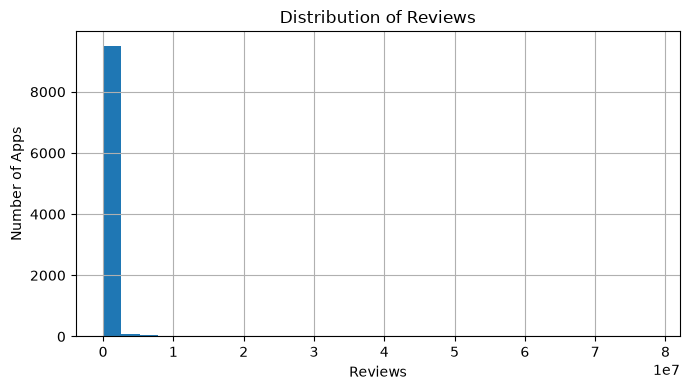

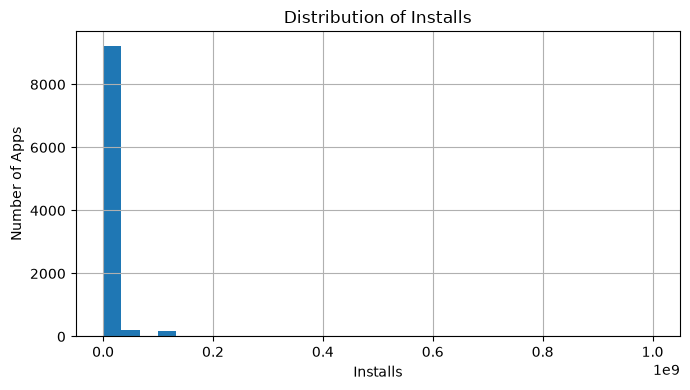

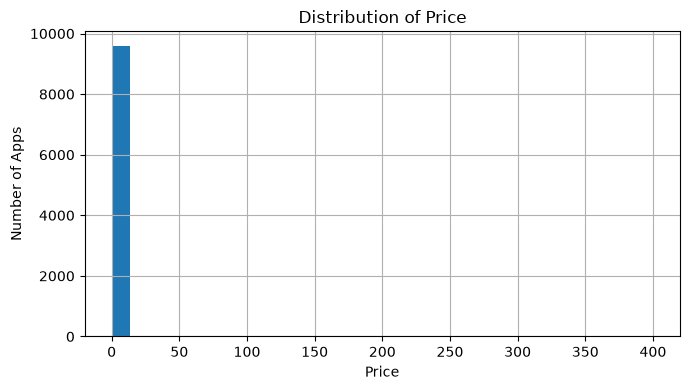

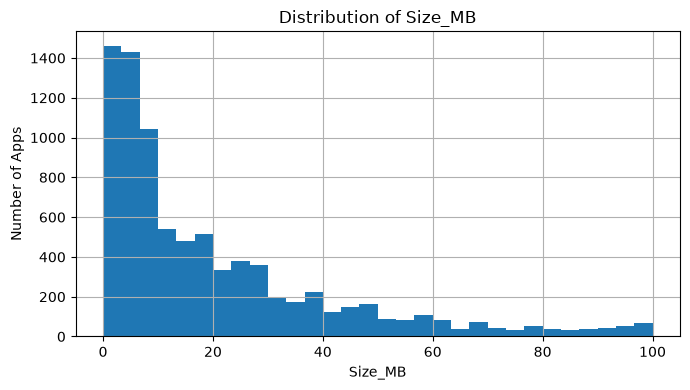

In [52]:

for col in numeric_columns:
    plt.figure(figsize=(7, 4))

    clean_df[col].dropna().hist(bins=30)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Apps")
    plt.tight_layout()
    plt.show()


**Numerical columns Observations**:
1: App ratings are generally high
2: Review counts are highly right-skewed; a few apps have very high review counts
3: Install counts are highly right-skewed; a few apps have very high install counts
4: App prices are concentrated at zero; most apps are free
5: Smaller apps are more common; smaller apps are more common

**Research questions:**
1. Which categories contain the most apps and the highest reported installs?
2. Which categories have the highest average ratings?
3. Do free and paid apps differ in ratings, reviews, and installs?
4. Is there a relationship between reviews and installs?
5. What are the pricing patterns among paid apps?
6. Which content-rating groups are most common?
7. Is app size associated with ratings or installs?
8. Are recently updated apps associated with higher ratings or installs?

**Question 1. Which categories contain the most apps and the highest reported installs?**

**Objective:** Identify the categories with the largest number of apps and the highest total reported installs.
**Hypothesis:** App counts and reported installs vary across categories.

In [53]:
# Question 1: Category analysis

category_analysis = clean_df.groupby("Category").agg(
    Total_Apps=("App", "nunique"),
    Total_Installs=("Installs", "sum"),
    Median_Installs=("Installs", "median")
)

# Top 10 categories by app count
top_apps = category_analysis.sort_values(
    "Total_Apps", ascending=False
).head(10)

print("Top 10 Categories by Number of Apps")
display(top_apps)

# Top 10 categories by total reported installs
top_installs = category_analysis.sort_values(
    "Total_Installs", ascending=False
).head(10)

print("Top 10 Categories by Total Reported Installs")
display(top_installs)

Top 10 Categories by Number of Apps


,Total_Apps,Total_Installs,Median_Installs
Category,,,
FAMILY,1877,6236542505,50000.0
GAME,945,13447924415,1000000.0
TOOLS,829,8102771915,50000.0
BUSINESS,420,697164865,1000.0
MEDICAL,395,38293077,1000.0
PERSONALIZATION,376,1532494782,10000.0
PRODUCTIVITY,374,5793091369,100000.0
LIFESTYLE,369,503823539,10000.0
FINANCE,345,455348734,10000.0


Top 10 Categories by Total Reported Installs


,Total_Apps,Total_Installs,Median_Installs
Category,,,
GAME,945,13447924415,1000000.0
COMMUNICATION,315,11038276251,100000.0
TOOLS,829,8102771915,50000.0
FAMILY,1877,6236542505,50000.0
PRODUCTIVITY,374,5793091369,100000.0
SOCIAL,239,5487867902,100000.0
PHOTOGRAPHY,281,4658147655,1000000.0
VIDEO_PLAYERS,164,3931902720,1000000.0
TRAVEL_AND_LOCAL,219,2894887146,100000.0


**Visualizations**

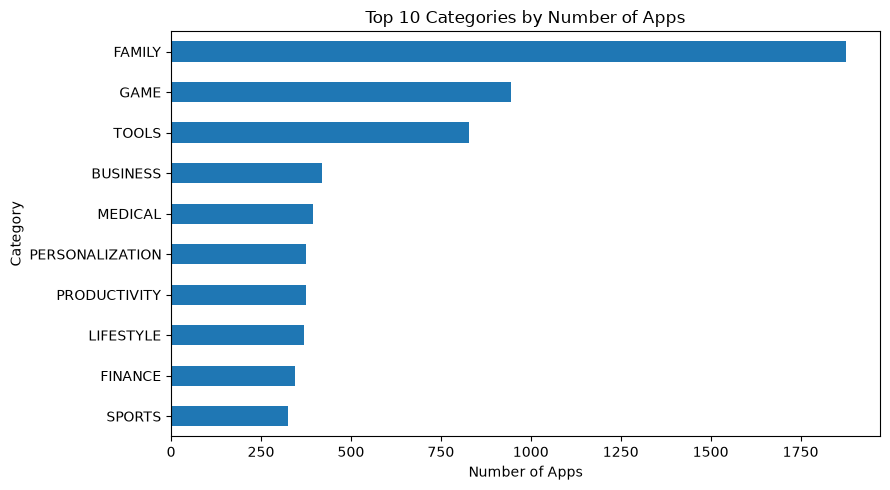

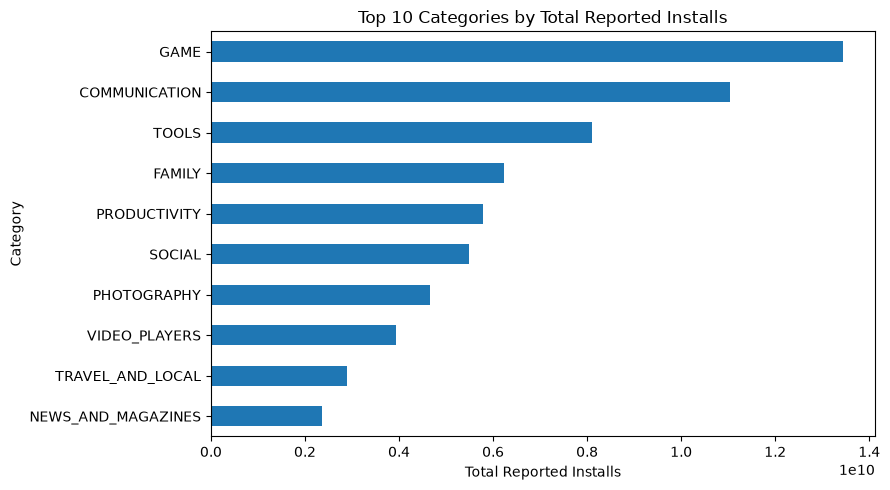

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

top_apps.sort_values("Total_Apps").plot(
    kind="barh", y="Total_Apps", legend=False, figsize=(9, 5)
)
plt.title("Top 10 Categories by Number of Apps")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

top_installs.sort_values("Total_Installs").plot(
    kind="barh", y="Total_Installs", legend=False, figsize=(9, 5)
)
plt.title("Top 10 Categories by Total Reported Installs")
plt.xlabel("Total Reported Installs")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

**Interpretation:**

**1. Categories with the most apps**

The FAMILY category has the highest number of apps, with 1,877 apps, followed by GAME with 945 apps and TOOLS with 829 apps.

Observation: FAMILY has the largest number of apps in the dataset, but having more apps does not necessarily mean having more installs.

**2. Categories with the highest total installs**

The GAME category has the highest total reported installs, at approximately 13.45 billion, followed by COMMUNICATION at 11.04 billion and TOOLS at 8.10 billion.

Observation: GAME apps have the highest combined reported installs, even though FAMILY has almost twice as many apps as GAME.

**3. Median installs**

GAME, PHOTOGRAPHY, and VIDEO_PLAYERS each have a median of 1,000,000 installs. This means the middle app in each of these categories has a reported install count of 1 million.

In comparison, FAMILY and TOOLS have median installs of 50,000.

**Observation:** Apps in GAME, PHOTOGRAPHY, and VIDEO_PLAYERS tend to have higher typical install counts than apps in FAMILY and TOOLS.

**Overall conclusion**
The FAMILY category contains the most apps, while GAME leads in total reported installs. This shows that the category with the most apps is not necessarily the category with the greatest reach. GAME also has a higher median install count, suggesting that its apps generally achieve higher reported installs.

**Question 2. Which categories have the highest average ratings?**

**Objective:** Compare user ratings across app categories.
**Hypothesis:** Average ratings differ between categories

In [55]:
# Question 2: Ratings by category

rating_by_category = (
    clean_df.dropna(subset=["Rating"])
    .groupby("Category")
    .agg(
        Average_Rating=("Rating", "mean"),
        Median_Rating=("Rating", "median"),
        Rated_Apps=("Rating", "count")
    )
)

# Avoid drawing conclusions from categories with very few rated apps
rating_by_category = rating_by_category[
    rating_by_category["Rated_Apps"] >= 30
]

rating_by_category = rating_by_category.sort_values(
    "Average_Rating", ascending=False
)

print("Top 10 Categories by Average Rating")
display(rating_by_category.head(10).round(2))

print("Bottom 10 Categories by Average Rating")
display(rating_by_category.tail(10).round(2))

Top 10 Categories by Average Rating


,Average_Rating,Median_Rating,Rated_Apps
Category,,,
EVENTS,4.44,4.5,45
ART_AND_DESIGN,4.36,4.4,59
EDUCATION,4.35,4.4,105
BOOKS_AND_REFERENCE,4.34,4.5,169
PERSONALIZATION,4.33,4.4,298
PARENTING,4.30,4.4,50
BEAUTY,4.28,4.3,42
SOCIAL,4.25,4.3,203
GAME,4.24,4.3,898


Bottom 10 Categories by Average Rating


,Average_Rating,Median_Rating,Rated_Apps
Category,,,
NEWS_AND_MAGAZINES,4.12,4.2,204
COMMUNICATION,4.12,4.2,256
FINANCE,4.12,4.3,302
BUSINESS,4.10,4.2,263
LIFESTYLE,4.09,4.2,301
TRAVEL_AND_LOCAL,4.07,4.2,187
VIDEO_PLAYERS,4.04,4.2,149
TOOLS,4.04,4.2,720
MAPS_AND_NAVIGATION,4.04,4.2,118


**Visualization**

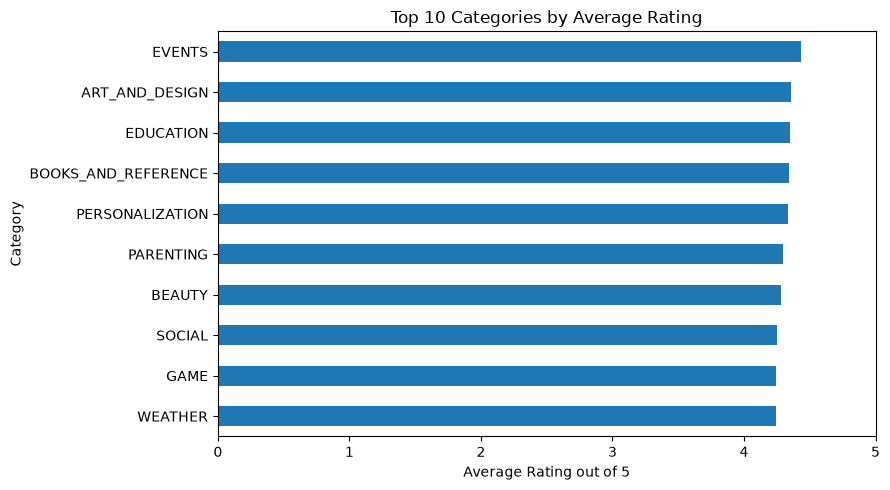

In [56]:
rating_by_category.head(10).sort_values(
    "Average_Rating"
).plot(
    kind="barh",
    y="Average_Rating",
    legend=False,
    figsize=(9, 5)
)

plt.title("Top 10 Categories by Average Rating")
plt.xlabel("Average Rating out of 5")
plt.ylabel("Category")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

**Interpretation:**

**1. Categories with the highest rating**

The EVENTS category has the highest average rating of 4.44, followed by ART_AND_DESIGN at 4.36 and EDUCATION at 4.35.

**Observation:** Apps in these categories receive relatively high user ratings, suggesting that users generally rate them positively.

**2. Categories with the lowest ratings**

The DATING category has the lowest average rating at 3.98, followed by VIDEO_PLAYERS, TOOLS, and MAPS_AND_NAVIGATION, each with an average rating of 4.04.

**Observation:** Compared with other categories, these categories have lower average ratings, which may indicate opportunities to improve user experience or app quality.

**3. Average rating vs. median rating**

Most categories have median ratings between 4.1 and 4.5. For example, BOOKS_AND_REFERENCE has an average rating of 4.34 and a median rating of 4.5.

**Observation:** Ratings are generally high across categories, although some apps with lower ratings can bring down the average.

**Overall conclusion**
The EVENTS category has the highest average rating, while DATING has the lowest. Overall, most categories have average ratings above 4.0, suggesting that users generally rate apps positively in this dataset.

However, EVENTS has only 45 rated apps, while TOOLS has 720. The number of rated apps should be considered when comparing categories because categories with fewer ratings may be less representative

**Question 3. Do free and paid apps differ in ratings, reviews, and installs?**

**Objective:** Compare free and paid apps across three performance measures.
**Hypothesis:** Free and paid apps have different rating, review, and install distributions.

In [57]:
# Question 3: Free vs paid apps

comparison = clean_df.groupby("Type").agg(
    App_Count=("App", "nunique"),
    Average_Rating=("Rating", "mean"),
    Median_Rating=("Rating", "median"),
    Average_Reviews=("Reviews", "mean"),
    Median_Reviews=("Reviews", "median"),
    Average_Installs=("Installs", "mean"),
    Median_Installs=("Installs", "median")
)

print("Free vs Paid App Comparison")
display(comparison.round(2))

Free vs Paid App Comparison


,App_Count,Average_Rating,Median_Rating,Average_Reviews,Median_Reviews,Average_Installs,Median_Installs
Type,,,,,,,
Free,8904,4.17,4.3,234446.87,1379.5,8452960.76,100000.0
Paid,754,4.26,4.4,8748.01,88.5,76079.29,1000.0


**Visualizations**

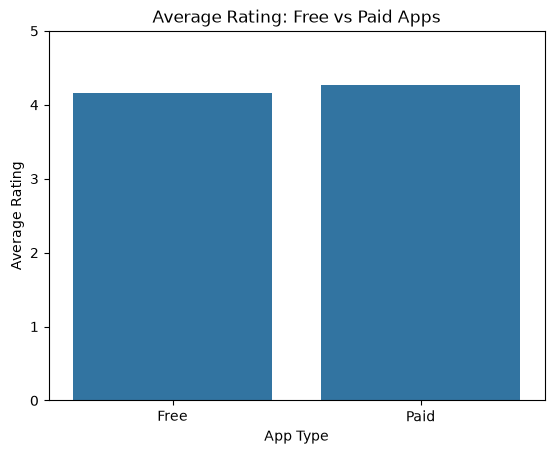

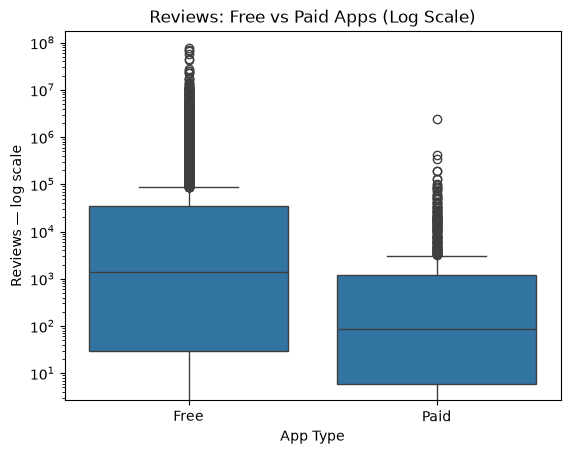

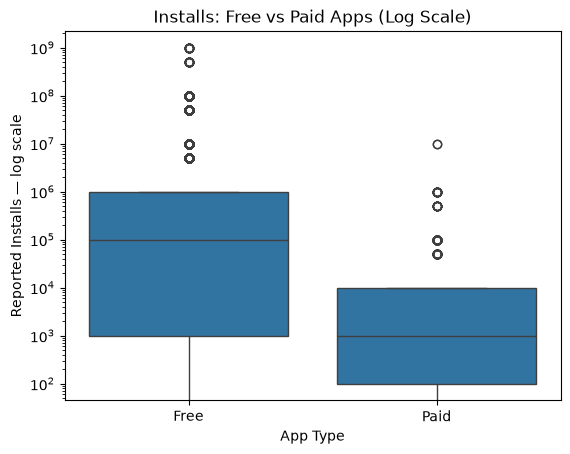

In [58]:
# Average ratings
sns.barplot(data=clean_df, x="Type", y="Rating", errorbar=None)
plt.title("Average Rating: Free vs Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.show()

# Reviews are highly skewed, so use a logarithmic axis
sns.boxplot(data=clean_df, x="Type", y="Reviews")
plt.yscale("log")
plt.title("Reviews: Free vs Paid Apps (Log Scale)")
plt.xlabel("App Type")
plt.ylabel("Reviews — log scale")
plt.show()

# Installs are also highly skewed
sns.boxplot(data=clean_df, x="Type", y="Installs")
plt.yscale("log")
plt.title("Installs: Free vs Paid Apps (Log Scale)")
plt.xlabel("App Type")
plt.ylabel("Reported Installs — log scale")
plt.show()

**Interpretation:** 

**1. Number of free vs paid apps**

There are 8,904 free apps and 754 paid apps in the dataset.

**Observation:** Free apps are much more common than paid apps. This suggests that offering apps for free is the more common pricing model in this dataset.

**2. Average ratings**

Paid apps have a slightly higher average rating of 4.26, compared with 4.17 for free apps.

**Observation:** Paid apps receive slightly higher ratings on average. However, this does not prove that users prefer paid apps, or that charging money leads to better ratings.

**3. Reviews**

Free apps have a median of 1,379.5 reviews, compared with only 88.5 reviews for paid apps.

**Observation:** Free apps generally have more reviews. One possible reason is that free apps are accessible to a wider audience, but this dataset alone cannot confirm the reason.

**4. Installs**

Free apps have a median of 100,000 installs, while paid apps have a median of 1,000 installs.

**Observation:** Free apps generally have higher reported install counts than paid apps. The price barrier may be one factor, although other factors such as app popularity, quality, and marketing could also influence installs.

**Overall conclusion**
Free apps are much more common and have substantially higher median reviews and installs than paid apps. Paid apps have a slightly higher average rating, at 4.26 compared with 4.17 for free apps.

This suggests that free apps reach a wider audience, while paid apps have slightly higher average ratings in this dataset. These are observed differences, not proof that pricing causes higher ratings or installs.

**Question 4. Is there a relationship between reviews and installs?**

**Objective:** Investigate whether apps with more reviews tend to have higher reported install counts.
**Hypothesis:** Reviews and reported installs have a positive relationship.

In [59]:
# Question 4: Relationship between reviews and installs

review_install_data = clean_df[
    ["Reviews", "Installs"]
].dropna()

# Pearson correlation using original values
raw_correlation = review_install_data[
    "Reviews"
].corr(review_install_data["Installs"])

# Log transformation helps handle highly skewed values
review_install_data = review_install_data.copy()
review_install_data["Log_Reviews"] = np.log1p(
    review_install_data["Reviews"]
)
review_install_data["Log_Installs"] = np.log1p(
    review_install_data["Installs"]
)

log_correlation = review_install_data[
    "Log_Reviews"
].corr(review_install_data["Log_Installs"])

print("Correlation using original values:", round(raw_correlation, 3))
print("Correlation using log-transformed values:", round(log_correlation, 3))

Correlation using original values: 0.625
Correlation using log-transformed values: 0.959


**Visualizations**

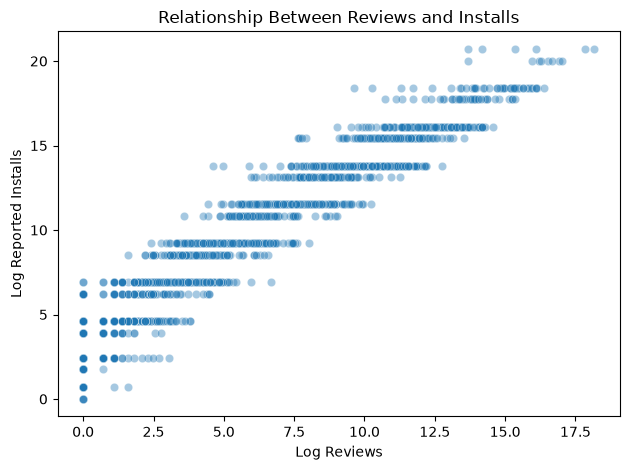

In [60]:
sns.scatterplot(
    data=review_install_data.sample(
        n=min(2000, len(review_install_data)),
        random_state=42
    ),
    x="Log_Reviews",
    y="Log_Installs",
    alpha=0.4
)

plt.title("Relationship Between Reviews and Installs")
plt.xlabel("Log Reviews")
plt.ylabel("Log Reported Installs")
plt.tight_layout()
plt.show()

**Interpretation:** 

**1. Correlation using original values: 0.625**
There is a positive relationship between reviews and installs. Apps with more reviews tend to have higher reported install counts.

**2. Correlation using log-transformed values: 0.959**
After applying a logarithmic transformation, the correlation becomes much stronger. This suggests that reviews and installs follow a very strong positive relationship when comparing their values on a logarithmic scale.

**Overall conclusion**
The analysis shows that apps with higher reported installs generally also have more reviews. The original correlation of 0.625 indicates a moderately strong positive relationship, while the log-transformed correlation of 0.959 indicates a very strong positive linear relationship on the transformed scale.

**Question 5. What are the pricing patterns among paid apps?**

**Objective:** Understand the typical price of paid apps and identify categories with higher-priced apps.
**Hypothesis:** Paid app prices vary across categories, and a small number of apps may have unusually high prices.

In [61]:
# Question 5: Pricing analysis

paid_apps = clean_df[
    (clean_df["Type"] == "Paid") &
    (clean_df["Price"] > 0)
].copy()

print("Paid Apps Price Summary")
display(paid_apps["Price"].describe().round(2))

print("Median price:", round(paid_apps["Price"].median(), 2))
print("Maximum price:", round(paid_apps["Price"].max(), 2))

# Top categories by median price
price_by_category = paid_apps.groupby("Category").agg(
    Paid_App_Count=("App", "nunique"),
    Median_Price=("Price", "median"),
    Average_Price=("Price", "mean"),
    Maximum_Price=("Price", "max")
)

# Only compare categories with at least 5 paid apps
price_by_category = price_by_category[
    price_by_category["Paid_App_Count"] >= 5
]

price_by_category = price_by_category.sort_values(
    "Median_Price", ascending=False
)

print("Categories with Highest Median Paid-App Prices")
display(price_by_category.head(10).round(2))

Paid Apps Price Summary


count    754.0
mean     14.06
std      58.82
min       0.99
25%       1.49
50%       2.99
75%       4.99
max      400.0
Name: Price, dtype: Float64

Median price: 2.99
Maximum price: 400.0
Categories with Highest Median Paid-App Prices


,Paid_App_Count,Median_Price,Average_Price,Maximum_Price
Category,,,,
FINANCE,17,28.99,170.64,399.99
BOOKS_AND_REFERENCE,28,5.04,4.28,6.49
BUSINESS,12,4.99,14.61,89.99
LIFESTYLE,19,4.99,124.26,400.0
MEDICAL,82,4.99,11.98,200.0
DATING,5,3.99,4.09,7.99
WEATHER,8,3.49,4.05,6.99
TRAVEL_AND_LOCAL,12,3.49,4.16,8.99
PHOTOGRAPHY,19,3.49,6.23,29.99


**Visualizations**

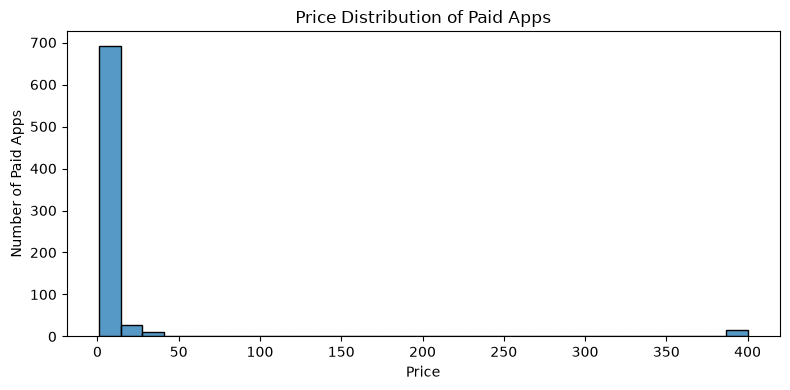

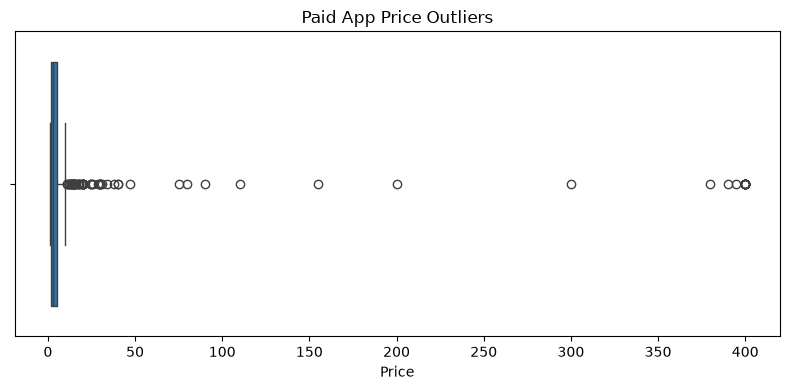

In [62]:
# Price distribution
plt.figure(figsize=(8, 4))
sns.histplot(paid_apps["Price"], bins=30)
plt.title("Price Distribution of Paid Apps")
plt.xlabel("Price")
plt.ylabel("Number of Paid Apps")
plt.tight_layout()
plt.show()

# Boxplot to identify unusually high prices
plt.figure(figsize=(8, 4))
sns.boxplot(x=paid_apps["Price"])
plt.title("Paid App Price Outliers")
plt.xlabel("Price")
plt.tight_layout()
plt.show()

**Interpretation:** 

**1. Typical price of paid apps**

The average price of paid apps is 14.06, while the median price is only 2.99.

**Observation:** Most paid apps are relatively inexpensive. The average is much higher than the median because a few apps have very high prices.

**2. Price distribution**

- 25% of paid apps cost 1.49 or less.
- 50% cost 2.99 or less.
- 75% cost 4.99 or less.
- The maximum listed price is 400.

**Observation:** Most paid apps are priced below 5, while a small number of expensive apps increase the overall average.

**3. Categories with the highest median prices**

The FINANCE category has the highest median price at 28.99, followed by BOOKS_AND_REFERENCE at 5.04. BUSINESS, LIFESTYLE, and MEDICAL have median prices around 4.99.

**Observation:** Paid apps in the FINANCE category are generally more expensive than paid apps in the other categories listed. However, FINANCE has only 17 paid apps, so its result should be interpreted with some caution.

**4. Unusually high prices**

The LIFESTYLE category has a maximum price of 400, while FINANCE reaches 399.99. These high prices also explain why the average price is much higher than the median in those categories.

**Observation:** A few expensive apps may strongly influence the average price. It is useful to examine these apps individually before drawing conclusions.

**Overall conclusion**
Most paid apps in the dataset are affordable, with a median price of 2.99 and 75% priced at 4.99 or less. FINANCE has the highest median price among the categories shown, while a few unusually expensive apps increase the overall average.

**Question 6. Which content-rating groups are most common?**

**Objective:** Understand the distribution of apps by their content-rating labels.
**Hypothesis:** Some content-rating groups are substantially more common than others.

In [63]:
# Question 6: Content-rating analysis

content_counts = clean_df["Content Rating"].value_counts(
    dropna=False
)

content_percentages = (
    clean_df["Content Rating"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
)

content_summary = pd.DataFrame({
    "App_Count": content_counts,
    "Percentage": content_percentages
})

print("Apps by Content Rating")
display(content_summary.round(2))

Apps by Content Rating


,App_Count,Percentage
Content Rating,,
Everyone,7903,81.82
Teen,1036,10.73
Mature 17+,393,4.07
Everyone 10+,322,3.33
Adults only 18+,3,0.03
Unrated,2,0.02


**Visualizations**

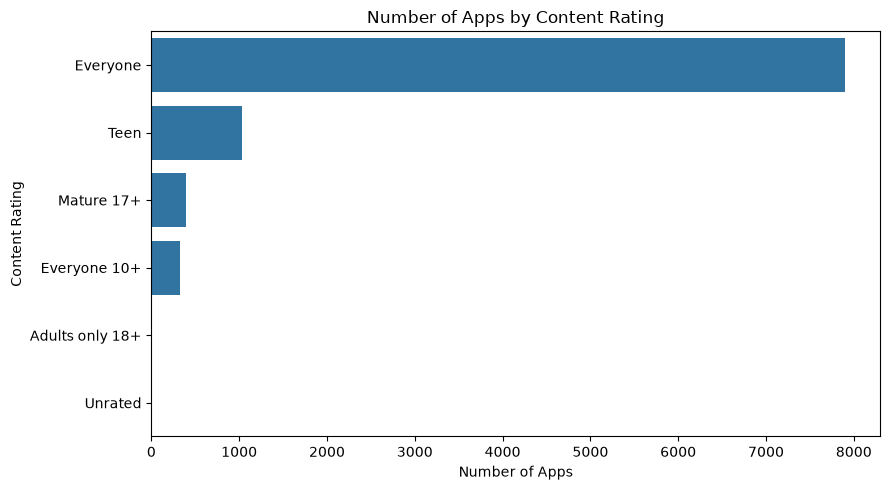

In [64]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=clean_df,
    y="Content Rating",
    order=clean_df["Content Rating"].value_counts().index
)

plt.title("Number of Apps by Content Rating")
plt.xlabel("Number of Apps")
plt.ylabel("Content Rating")
plt.tight_layout()
plt.show()

**Interpretation:** 

1. Everyone is the most common content rating, representing 7,903 apps (81.82%). This indicates that most apps in the dataset are classified as suitable for users of all ages.

2. Teen is the second most common category, with 1,036 apps (10.73%).

3. Mature 17+ accounts for 4.07% of apps, with 393 apps.

4. Everyone 10+ represents 3.33% of apps, with 322 apps.

5. Adults only 18+ and Unrated are extremely rare, together accounting for just 5 apps (approximately 0.05%).

**Key finding:**
The dataset is heavily dominated by apps rated Everyone, which make up more than four-fifths of all apps. Teen-rated apps form the second-largest group, while apps with stricter age restrictions represent a much smaller share.

**Question 7. Is app size associated with ratings or installs?**

**Objective:** Explore whether app size is related to ratings or reported install counts.
**Hypothesis:** App size may be associated with ratings and/or installs, but the direction and strength of the relationship need to be tested.

In [65]:
# Question 7: App size and performance

size_data = clean_df[
    ["Size_MB", "Rating", "Installs"]
].dropna(subset=["Size_MB"]).copy()

# Correlation with ratings
rating_size_data = size_data.dropna(subset=["Rating"])

rating_size_corr = rating_size_data[
    "Size_MB"
].corr(rating_size_data["Rating"])

# Log transformation for installs
size_data["Log_Installs"] = np.log1p(size_data["Installs"])

install_size_data = size_data.dropna(subset=["Installs"])

install_size_corr = install_size_data[
    "Size_MB"
].corr(install_size_data["Log_Installs"])

print("Correlation between app size and rating:",
      round(rating_size_corr, 3))

print("Correlation between app size and log installs:",
      round(install_size_corr, 3))

Correlation between app size and rating: 0.063
Correlation between app size and log installs: 0.3


**Visualizations**

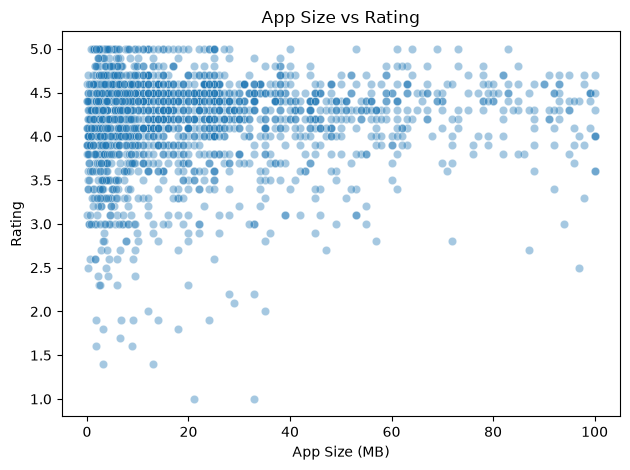

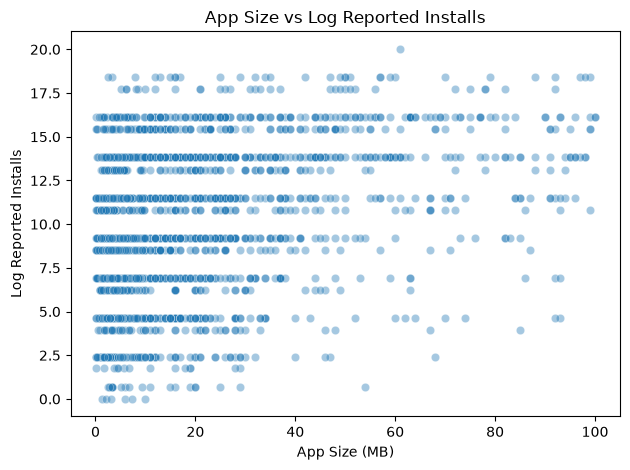

In [66]:
# App size vs rating
sns.scatterplot(
    data=rating_size_data.sample(
        n=min(2000, len(rating_size_data)),
        random_state=42
    ),
    x="Size_MB",
    y="Rating",
    alpha=0.4
)

plt.title("App Size vs Rating")
plt.xlabel("App Size (MB)")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

# App size vs installs
sns.scatterplot(
    data=install_size_data.sample(
        n=min(2000, len(install_size_data)),
        random_state=42
    ),
    x="Size_MB",
    y="Log_Installs",
    alpha=0.4
)

plt.title("App Size vs Log Reported Installs")
plt.xlabel("App Size (MB)")
plt.ylabel("Log Reported Installs")
plt.tight_layout()
plt.show()

**Interpretation:** 

**1. App size and rating: 0.063**
This indicates a very weak positive correlation, almost zero. App size has little to no linear relationship with app ratings in this dataset. Larger apps are not necessarily rated better.

**2. App size and log installs: 0.300**
This indicates a weak positive correlation. Larger apps tend to have somewhat higher installs, but the relationship is not strong. Other factors may also influence downloads, such as app category, popularity, features, and marketing.

**Key finding for your project**
App size has almost no relationship with ratings, while its relationship with log-transformed installs is weakly positive. Therefore, app size alone is not a strong indicator of app ratings or download performance.

**Question 8. Are recently updated apps associated with higher ratings or installs?**

**Objective:** Explore whether the year of the last update is associated with app ratings and reported installs.
**Hypothesis:** Average ratings and reported installs differ across app update years.

In [67]:
# Question 8: Update year analysis

update_data = clean_df.dropna(
    subset=["Update_Year"]
).copy()

yearly_analysis = update_data.groupby("Update_Year").agg(
    Total_Apps=("App", "nunique"),
    Average_Rating=("Rating", "mean"),
    Median_Rating=("Rating", "median"),
    Median_Installs=("Installs", "median")
)

print("App Performance by Last-Updated Year")
display(yearly_analysis.round(2))

App Performance by Last-Updated Year


,Total_Apps,Average_Rating,Median_Rating,Median_Installs
Update_Year,,,,
2010,1,4.20,4.2,100000.0
2011,15,3.97,4.0,50000.0
2012,26,3.79,4.0,75000.0
2013,108,4.07,4.1,10000.0
2014,203,4.03,4.1,10000.0
2015,448,4.06,4.1,10000.0
2016,779,4.04,4.2,10000.0
2017,1792,4.09,4.2,10000.0
2018,6287,4.23,4.3,100000.0


**Visualizations**

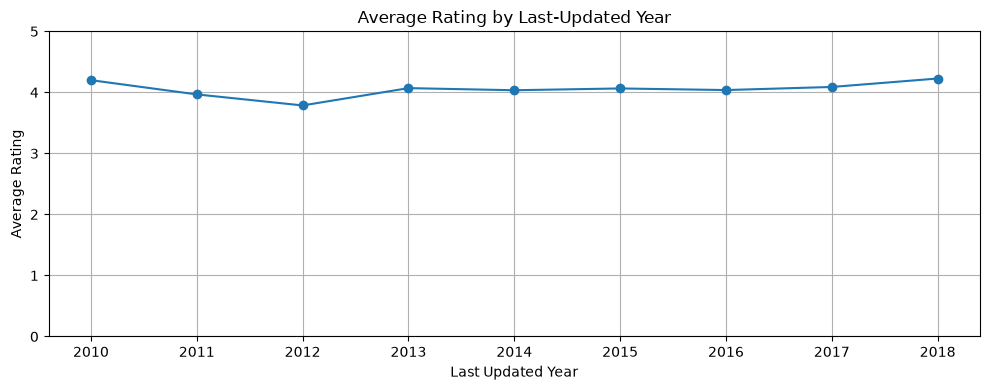

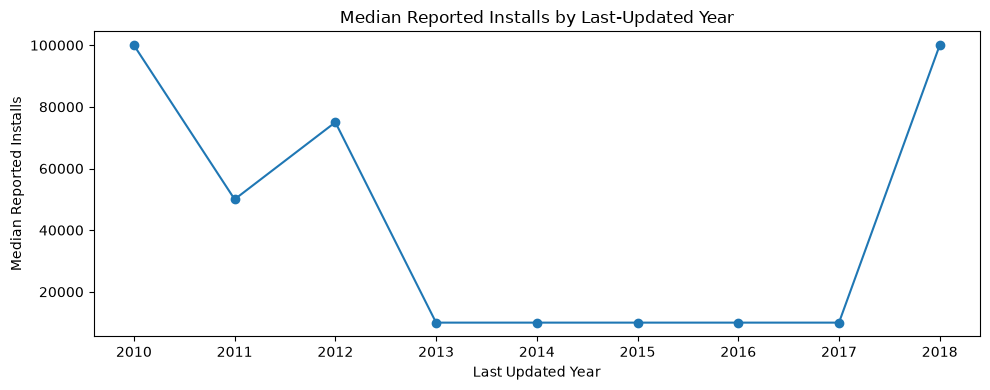

In [68]:
# Average rating by update year
yearly_analysis["Average_Rating"].plot(
    kind="line", marker="o", figsize=(10, 4)
)

plt.title("Average Rating by Last-Updated Year")
plt.xlabel("Last Updated Year")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.grid(True)
plt.tight_layout()
plt.show()

# Median installs by update year
yearly_analysis["Median_Installs"].plot(
    kind="line", marker="o", figsize=(10, 4)
)

plt.title("Median Reported Installs by Last-Updated Year")
plt.xlabel("Last Updated Year")
plt.ylabel("Median Reported Installs")
plt.tight_layout()
plt.show()

**Interpretation:** 

1. 2018 has the highest average rating among the years shown, at 4.23, and the highest median rating, at 4.3. This suggests that apps last updated in 2018 generally had good ratings.

2. Apps last updated in 2018 also have the highest median installs, at 100,000, equal to the 2010 group. This suggests that the 2018-updated apps in this dataset had relatively strong download numbers.

3. Apps updated between 2013 and 2017 have median installs of 10,000. Their average ratings remain fairly stable, mostly around 4.03–4.09.

4. The number of apps varies considerably by year. There are 6,287 apps in the 2018 group, compared with just 1 app in 2010. Results for years with very few apps may not be representative.

**Key finding:**
In this dataset, apps last updated in 2018 show higher average ratings and median installs than most apps in earlier update-year groups. However, this does not prove that updating an app causes better performance. App popularity, category, app age, and other factors may influence the results.

**Conclusion:** 

**1. App category distribution:** FAMILY has the highest number of apps, while GAME has the highest total reported installs. This shows that the category with the most apps is not necessarily the category with the greatest reach.

**2. App ratings:** EVENTS has the highest average rating at 4.44, while DATING has the lowest at 3.98 among the categories analyzed. Most categories have average ratings above 4.0, suggesting generally positive user ratings.

**3. Free vs. paid apps:** Free apps are much more common and have substantially higher median installs and reviews than paid apps. Paid apps have a slightly higher average rating (4.26 compared with 4.17 for free apps).

**4. Reviews and installs:** Reviews and installs have a positive relationship. The correlation is 0.625 using the original values and 0.959 after log transformation, indicating a very strong linear relationship on the log-transformed scale.

**5. App pricing:** Most paid apps are relatively affordable. The median price is 2.99, and 75% of paid apps are priced at 4.99 or below. A few expensive apps increase the average price considerably.

**6. Content ratings:** The Everyone category dominates the dataset, representing 81.82% of apps. Teen-rated apps are the second-largest group at 10.73%.

**7. App size and performance:** App size has almost no linear relationship with ratings (correlation 0.063) and a weak positive relationship with log installs (correlation 0.300). App size alone is not a strong indicator of performance.

**8. Last-updated year:** Apps last updated in 2018 have an average rating of 4.23 and median installs of 100,000. However, this does not prove that recent updates improve performance, and the dataset's latest update year is 2018.

**Limitations of the Analysis**
- The dataset is old, with the latest update year shown being 2018, so the findings may not represent today's Google Play Store.
- Install counts are reported in rounded ranges, so total installs are approximate.
- Correlation indicates association, not cause and effect.
- Some categories contain relatively few apps, which can make their average ratings or prices less reliable.

**Overall Summary**
This exploratory analysis shows that app performance varies across categories and pricing models. Free apps generally reach more users, apps with more reviews tend to have more installs, and most apps are rated for a broad audience. However, no single factor—such as price, app size, or update year—fully explains app performance. A combination of app characteristics and user engagement metrics provides a more useful basis for understanding the dataset.


**Step 1 — Export your cleaned dataset from Python**

In [71]:
clean_df.to_csv("google_playstore_cleaned.csv", index=False)

In [72]:
import os
print(os.getcwd())

C:\Users\Sukanya


In [73]:
import os

print(os.getcwd())
print(os.path.abspath("google_playstore_cleaned.csv"))
print(os.path.exists("google_playstore_cleaned.csv"))

C:\Users\Sukanya
C:\Users\Sukanya\google_playstore_cleaned.csv
True


In [74]:
print("Total rows in clean_df:", len(clean_df))
print("Total columns in clean_df:", len(clean_df.columns))

Total rows in clean_df: 9659
Total columns in clean_df: 15


In [75]:
clean_df.to_csv(
    r"C:\Users\Sukanya\google_playstore_cleaned.csv",
    index=False
)

In [76]:
import pandas as pd

check_df = pd.read_csv(
    r"C:\Users\Sukanya\google_playstore_cleaned.csv"
)

print("Rows saved:", len(check_df))
print("Columns saved:", len(check_df.columns))

Rows saved: 9659
Columns saved: 15
